# Chicago Public Schools (2011-12): SQL Analysis of Safety, Attendance and Enrollment

**Question:** What does the Chicago Public Schools progress-report dataset reveal about school safety, student attendance and enrollment, and what traps does a *real* dataset set for anyone querying it with SQL?

**Approach:** load two CSVs (566 schools x 78 columns, plus Chicago census data) into **SQLite**, inspect the catalog, then answer 12 analytical questions with SQL (filters, aggregates, sorting, sub-queries, joins) and interpret the results.

**Headline findings**

1. **Attendance splits sharply by school type.** The top 10 attendance rates (97.2-98.4%) all belong to elementary-level schools, six of them selective programs (magnet, gifted, classical, language academy). Of the 8 schools below 70%, **7 are high schools**.
2. **Safety scores span almost the whole scale**: 19 schools tie at the maximum of 99, while the lowest is **1**.
3. **Enrollment is concentrated**: the 10 biggest of 77 community areas hold **29%** of all enrolled students; the largest (South Lawndale, 14,793) is **106x** the smallest (Oakland, 140).
4. **Real data is messy**: 59 of 78 columns are stored as text (including percentages like `'96.00%'`), missing values sort *first* in SQLite, and one lab question has two defensible readings.

> All results below come from the original run of the queries on the full dataset. When `RealWorldData.db` exists next to this notebook (build it with `python run_pipeline.py`), every cell re-runs the SQL live instead.

## 1. Setup

In [1]:
import sys, sqlite3
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from src import chicago_sql as cs

pd.set_option("display.max_colwidth", 70)
DB = ROOT / "RealWorldData.db"
LIVE = DB.exists()
con = sqlite3.connect(DB) if LIVE else None
verified = cs.load_verified()
meta = cs.load_verified_meta()
print("Mode:", "LIVE - running SQL against RealWorldData.db" if LIVE else "SNAPSHOT - showing results captured from the original run")

def problem(pid, show_sql=True):
    """Show the SQL for a problem and return its result (live if the database exists, else captured)."""
    m = meta[pid]
    sql_text = (ROOT / m["sql_file"]).read_text()
    if show_sql:
        display(Markdown(f"```sql\n{sql_text.strip()}\n```"))
    return cs.run_sql(con, sql_text) if LIVE else verified[pid]

Mode: SNAPSHOT - showing results captured from the original run


## 2. Data model: what are we working with?

`pandas.DataFrame.to_sql()` turns each CSV into a SQLite table: **`CHICAGO_PUBLIC_SCHOOLS_DATA`** (one row per school) and **`CENSUS_DATA`** (one row per community area, used for the join problems). The table has **566 rows** (the row count returned by the load step in the original run).

In [2]:
schema = cs.load_schema_snapshot()          # same output as SELECT ... FROM PRAGMA_TABLE_INFO(...)
print(f"{len(schema)} columns")
types = schema["declared_type"].value_counts().rename_axis("declared type").to_frame("columns")
types["share"] = (types["columns"] / len(schema)).map("{:.0%}".format)
display(types)

78 columns


,columns,share
declared type,,
TEXT,59,76%
REAL,12,15%
INTEGER,7,9%


**Insight - the table is mostly text.** 59 of 78 columns (76%) are declared `TEXT`. That includes values that are really numbers, such as attendance (`'96.00%'`), several score columns and grade-level percentages, so numeric analysis needs explicit `CAST(REPLACE(...))` steps. Only 12 columns are `REAL` and 7 `INTEGER`.

### Lab questions on naming

In [3]:
names = schema["column_name"]
print("1. School ID column:      ", names[names.str.upper() == "SCHOOL_ID"].tolist(), "-> mixed case")
print("2. Community area name:   ", names[names.str.upper() == "COMMUNITY_AREA_NAME"].tolist(), "-> no spaces")
with_space = names[names.str.contains(" ")].tolist()
underscored = names[names.str.contains(r"__|_$", regex=True)].tolist()
print(f"3. Spaces/parentheses replaced by '_' in {len(underscored)} columns, e.g.:", underscored[:4])
print(f"   ...but {len(with_space)} columns still contain spaces and need double quotes:", with_space)

1. School ID column:       ['School_ID'] -> mixed case
2. Community area name:    ['COMMUNITY_AREA_NAME'] -> no spaces
3. Spaces/parentheses replaced by '_' in 22 columns, e.g.: ['Adequate_Yearly_Progress_Made_', 'Rate_of_Misconducts__per_100_students_', 'Pk_2_Literacy__', 'Pk_2_Math__']
   ...but 6 columns still contain spaces and need double quotes: ['Elementary, Middle, or High School', '9th Grade EXPLORE (2009)', '9th Grade EXPLORE (2010)', '10th Grade PLAN (2009)', '10th Grade PLAN (2010)', '11th Grade Average ACT (2011)']


**Insight - inconsistent naming is a real hazard.** Most column names use underscores in place of spaces and parentheses (`Rate_of_Misconducts__per_100_students_`), but 6 were left with spaces (`"Elementary, Middle, or High School"`, `"9th Grade EXPLORE (2009)"`). Those need double quotes. SQLite identifiers are case-insensitive, so `SAFETY_SCORE`, `Safety_Score` and `safety_score` all work.

A look at one real row (Lane Technical High School) shows what the data looks like:

In [4]:
sample = pd.read_csv(ROOT / "data" / "sample_8_schools.csv")
cols = ["School_ID", "NAME_OF_SCHOOL", "Elementary, Middle, or High School", "SAFETY_SCORE",
        "AVERAGE_STUDENT_ATTENDANCE", "COLLEGE_ENROLLMENT", "COMMUNITY_AREA_NAME"]
display(sample.loc[sample["School_ID"] == 609720, cols].T.rename(columns={6: "value"}))

,value
School_ID,609720
NAME_OF_SCHOOL,Albert G Lane Technical High School
"Elementary, Middle, or High School",HS
SAFETY_SCORE,88.0
AVERAGE_STUDENT_ATTENDANCE,96.30%
COLLEGE_ENROLLMENT,4368
COMMUNITY_AREA_NAME,NORTH CENTER


## 3. School composition and safety (Problems 1-3, 10)

**Problem 1: how many elementary schools?** &nbsp; **Problem 2: highest safety score?** &nbsp; **Problem 3: which schools have it?**

In [5]:
p1 = problem('01'); display(p1)

```sql
-- Problem 1: How many elementary schools are in the dataset?
SELECT COUNT(*) AS elementary_schools
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
WHERE "Elementary, Middle, or High School" = 'ES';
```

,elementary_schools
0,462


In [6]:
p2 = problem('02'); display(p2)

```sql
-- Problem 2: What is the highest Safety Score?
SELECT MAX(Safety_Score) AS max_safety_score
FROM CHICAGO_PUBLIC_SCHOOLS_DATA;
```

,max_safety_score
0,99.0


In [7]:
p3 = problem('03'); display(p3)

```sql
-- Problem 3: Which schools have the highest Safety Score?
SELECT Name_of_School, Safety_Score
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
WHERE Safety_Score = (SELECT MAX(Safety_Score) FROM CHICAGO_PUBLIC_SCHOOLS_DATA);
```

,name_of_school,safety_score
0,Abraham Lincoln Elementary School,99.0
1,Alexander Graham Bell Elementary School,99.0
2,Annie Keller Elementary Gifted Magnet School,99.0
3,Augustus H Burley Elementary School,99.0
4,Edgar Allan Poe Elementary Classical School,99.0
5,Edgebrook Elementary School,99.0
6,Ellen Mitchell Elementary School,99.0
7,James E McDade Elementary Classical School,99.0
8,James G Blaine Elementary School,99.0
9,LaSalle Elementary Language Academy,99.0


In [8]:
n_es, n_total = int(p1.iloc[0, 0]), 566
is_hs = p3["name_of_school"].str.contains("High School")
print(f"Elementary schools: {n_es} of {n_total} = {n_es / n_total:.1%}")
print(f"Schools tied at the top safety score: {len(p3)}  (elementary-level {int((~is_hs).sum())}, high school {int(is_hs.sum())})")

Elementary schools: 462 of 566 = 81.6%
Schools tied at the top safety score: 19  (elementary-level 17, high school 2)


**Insight.** Elementary schools make up **81.6%** of the dataset (462 of 566), so any citywide average is dominated by them. The maximum safety score is **99**, shared by **19 schools** (17 elementary-level, 2 high schools), so a plain `MAX()` hides how many schools tie. Problem 3 uses a sub-query (`= (SELECT MAX(...))`) instead of hard-coding 99, which keeps the query correct if the data changes.

**Problem 10: the five lowest safety scores.**

In [9]:
p10 = problem('10'); display(p10)

```sql
-- Problem 10: 5 schools with the lowest safety score
SELECT name_of_school, safety_score
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
WHERE safety_score != 'None'
ORDER BY safety_score
LIMIT 5;
```

,name_of_school,safety_score
0,Edmond Burke Elementary School,1.0
1,Luke O'Toole Elementary School,5.0
2,George W Tilton Elementary School,6.0
3,Foster Park Elementary School,11.0
4,Emil G Hirsch Metropolitan High School,13.0


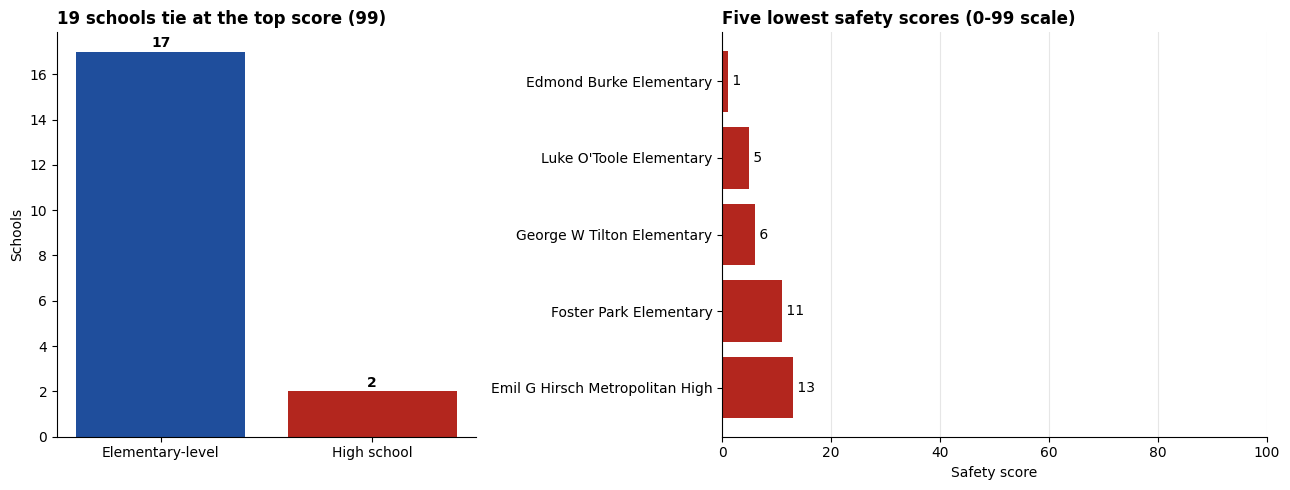

In [10]:
cs.plot_safety_extremes(p3, p10);

**Insight - a 98-point spread.** Scores range from **1** (Edmond Burke Elementary) to **99**, and four of the five lowest-scoring schools are elementary schools. Both the top-scoring group and the bottom-scoring group contain elementary schools and high schools, so school type alone does not explain safety.

*SQL note:* the lab's filter `safety_score != 'None'` works only by accident of SQLite semantics: a `NULL` compared to anything yields `NULL`, so missing rows drop out. The explicit and portable form is `WHERE safety_score IS NOT NULL`.

## 4. Student attendance (Problems 4-7)

Attendance is stored as **text** (`'98.40%'`), which shapes every query in this section.

In [11]:
p4 = problem('04'); display(p4)

```sql
-- Problem 4: Top 10 schools by average student attendance
SELECT Name_of_School, Average_Student_Attendance
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
ORDER BY Average_Student_Attendance DESC NULLS LAST
LIMIT 10;
```

,name_of_school,average_student_attendance
0,John Charles Haines Elementary School,98.40%
1,James Ward Elementary School,97.80%
2,Edgar Allan Poe Elementary Classical School,97.60%
3,Orozco Fine Arts & Sciences Elementary School,97.60%
4,Rachel Carson Elementary School,97.60%
5,Annie Keller Elementary Gifted Magnet School,97.50%
6,Andrew Jackson Elementary Language Academy,97.40%
7,Lenart Elementary Regional Gifted Center,97.40%
8,Disney II Magnet School,97.30%
9,John H Vanderpoel Elementary Magnet School,97.20%


**Insight.** The ten highest rates run from **98.4%** (John Charles Haines Elementary) to 97.2%, and every one is an elementary-level school. At least six carry a selective-program label in the name (Classical, Gifted, Magnet, Language Academy). `NULLS LAST` makes the intent explicit: SQLite already puts missing values last in descending order, but other engines (e.g. PostgreSQL) put them first, so spelling it out keeps the query portable.

**Problem 5: lowest five.**

In [12]:
p5 = problem('05'); display(p5)

```sql
-- Problem 5: 5 schools with the lowest average student attendance (ascending)
SELECT Name_of_School, Average_Student_Attendance
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
ORDER BY Average_Student_Attendance
LIMIT 5;
```

,name_of_school,average_student_attendance
0,Velma F Thomas Early Childhood Center,NaN
1,Richard T Crane Technical Preparatory High School,57.90%
2,Barbara Vick Early Childhood & Family Center,60.90%
3,Dyett High School,62.50%
4,Wendell Phillips Academy High School,63.00%


**Gotcha - the "lowest" school has no value at all.** *Velma F Thomas Early Childhood Center* appears first with attendance `None`: in SQLite, `NULL` sorts before every real value in ascending order. A reader skimming this result would wrongly conclude it has the worst attendance. The NULL-safe version (`E04` in `sql/extended`) filters `WHERE Average_Student_Attendance IS NOT NULL` and sorts on a numeric cast.

**Problem 6: strip the `%` sign.**

In [13]:
p6 = problem('06'); display(p6)

```sql
-- Problem 6: Same result set with the '%' sign removed
SELECT Name_of_School, REPLACE(Average_Student_Attendance, '%', '') AS attendance_pct
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
ORDER BY Average_Student_Attendance
LIMIT 5;
```

,name_of_school,attendance_pct
0,Velma F Thomas Early Childhood Center,NaN
1,Richard T Crane Technical Preparatory High School,57.90
2,Barbara Vick Early Childhood & Family Center,60.90
3,Dyett High School,62.50
4,Wendell Phillips Academy High School,63.00


`REPLACE(col, '%', '')` returns **text** (`'57.90'`), not a number. To compare numerically you must also `CAST` it, which is what Problem 7 does.

**Problem 7: schools below 70% attendance.**

In [14]:
p7 = problem('07'); display(p7)

```sql
-- Problem 7: Schools with average student attendance below 70%
SELECT Name_of_School, Average_Student_Attendance
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
WHERE CAST(REPLACE(Average_Student_Attendance, '%', '') AS DOUBLE) < 70
ORDER BY Average_Student_Attendance;
```

,name_of_school,average_student_attendance
0,Richard T Crane Technical Preparatory High School,57.90%
1,Barbara Vick Early Childhood & Family Center,60.90%
2,Dyett High School,62.50%
3,Wendell Phillips Academy High School,63.00%
4,Orr Academy High School,66.30%
5,Manley Career Academy High School,66.80%
6,Chicago Vocational Career Academy High School,68.80%
7,Roberto Clemente Community Academy High School,69.60%


8 schools below 70%: 7 high schools, 1 other
Others: ['Barbara Vick Early Childhood & Family Center']


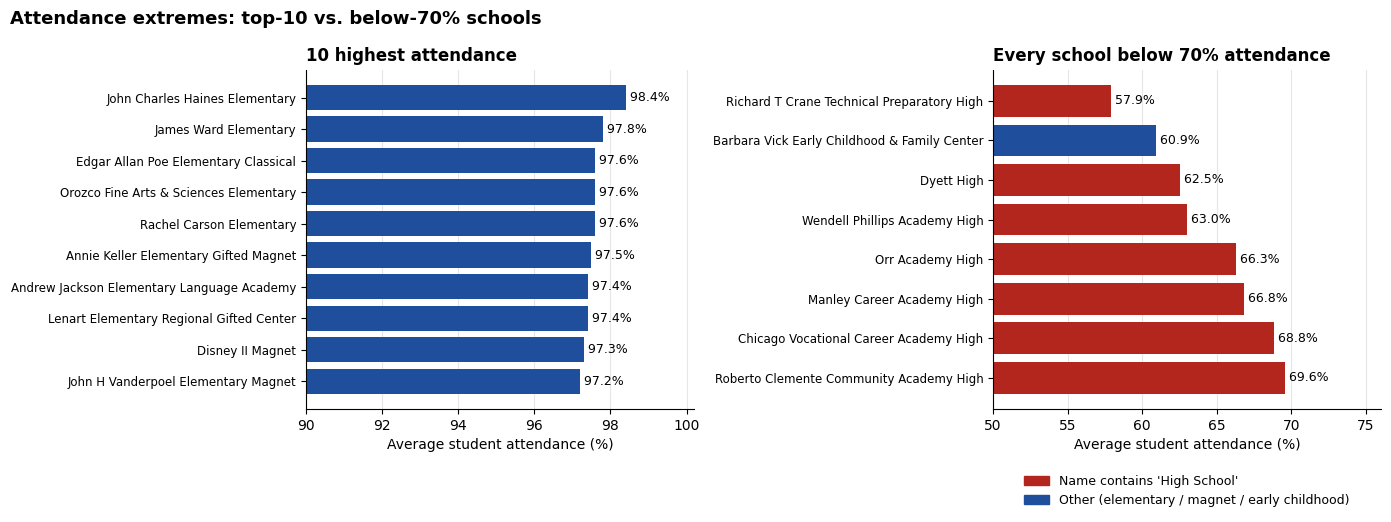

In [15]:
is_hs7 = p7["name_of_school"].str.contains("High School")
print(f"{len(p7)} schools below 70%: {int(is_hs7.sum())} high schools, {int((~is_hs7).sum())} other")
print("Others:", p7.loc[~is_hs7, "name_of_school"].tolist())
cs.plot_attendance_extremes(p4, p7);

**Insight - a 40-point gap, and it follows school type.** Only **8 schools** fall below 70%: **7 are high schools** (the lowest is Richard T. Crane Technical Preparatory at **57.9%**) and the eighth is an early-childhood center. The best elementary schools sit near 98%. High schools, not elementary schools, are where the city's attendance problem concentrates in this dataset.

*Caveat:* sorting a text column is lexicographic. It gives the right order here because every value has two digits before the decimal point; a `'100.00%'` would sort *before* `'57.90%'`. Casting to a number first is the safe habit.

## 5. Enrollment by community area (Problems 8-9)

A note on the column: `COLLEGE_ENROLLMENT` holds values like 813 and 1,324 for **elementary schools** in the sample rows, so it behaves like each school's student headcount, not "students enrolled in college". Totals below are therefore the **number of students enrolled in schools located in each community area** (schools with missing values are ignored by `SUM`).

In [16]:
p8 = problem('08'); print(len(p8), 'community areas'); display(p8.head(8))

```sql
-- Problem 8: Total college enrollment for each community area
SELECT Community_Area_Name, SUM(College_Enrollment) AS total_enrollment
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
GROUP BY Community_Area_Name;
```

77 community areas


,community_area_name,total_enrollment
0,ALBANY PARK,6864
1,ARCHER HEIGHTS,4823
2,ARMOUR SQUARE,1458
3,ASHBURN,6483
4,AUBURN GRESHAM,4175
5,AUSTIN,10933
6,AVALON PARK,1522
7,AVONDALE,3640


community_areas              77
total_enrollment             354,346
median                       4,206
mean                         4,602
largest_area                 SOUTH LAWNDALE
largest_total                14,793
smallest_area                OAKLAND
smallest_total               140
largest_to_smallest_ratio    105.664
top5_share                   0.168
top10_share                  0.287
bottom_half_share            0.244


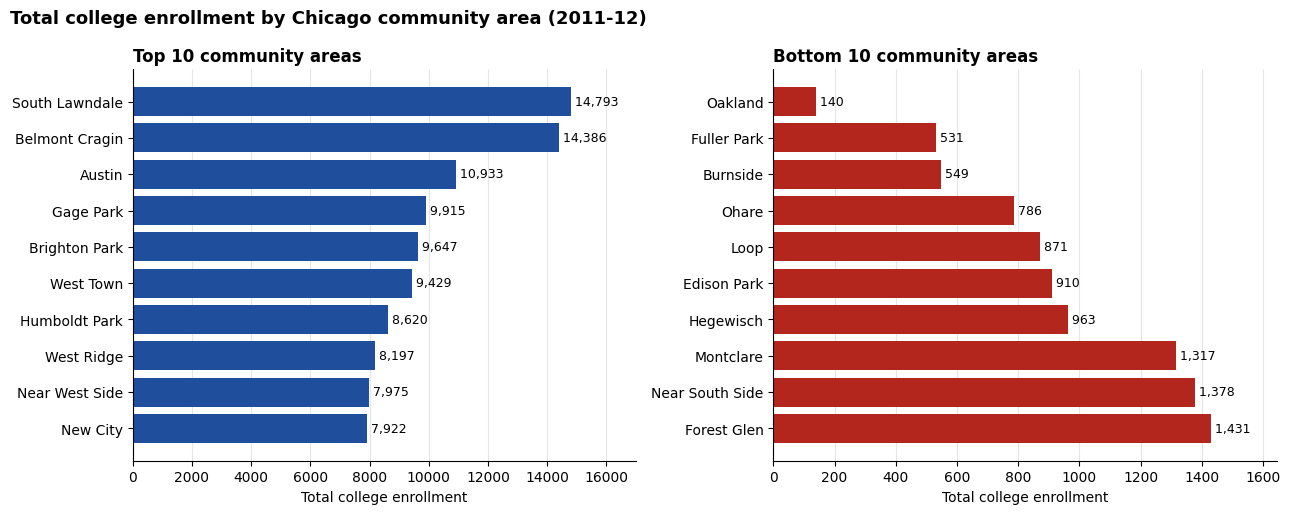

In [17]:
enroll = cs.load_enrollment_snapshot() if not LIVE else p8.rename(columns={"total_enrollment": "total_college_enrollment"})
stats = cs.enrollment_concentration(enroll)
for k in ["community_areas", "total_enrollment", "median", "mean", "largest_area", "largest_total",
          "smallest_area", "smallest_total", "largest_to_smallest_ratio", "top5_share", "top10_share", "bottom_half_share"]:
    v = stats[k]
    print(f"{k:28s}", f"{v:,.3f}" if isinstance(v, float) and v < 1000 and k not in ("median",) else (f"{v:,.0f}" if not isinstance(v, str) else v))
cs.plot_enrollment_extremes(enroll);

**Insight - enrollment is very unevenly spread.** Across the **77** community areas the total is **354,346** students. South Lawndale (**14,793**) and Belmont Cragin (**14,386**) lead, while Oakland has just **140**: a **106x** difference. The five largest areas hold 16.8% of the total and the ten largest hold **28.7%**, while the 38 smallest areas together hold only **24.4%**.

**Problem 9: five smallest.**

In [18]:
p9 = problem('09'); display(p9)

```sql
-- Problem 9: 5 community areas with the least total college enrollment
SELECT Community_Area_Name, SUM(College_Enrollment) AS total_enrollment
FROM CHICAGO_PUBLIC_SCHOOLS_DATA
GROUP BY Community_Area_Name
ORDER BY total_enrollment ASC
LIMIT 5;
```

,community_area_name,total_enrollment
0,OAKLAND,140
1,FULLER PARK,531
2,BURNSIDE,549
3,OHARE,786
4,LOOP,871


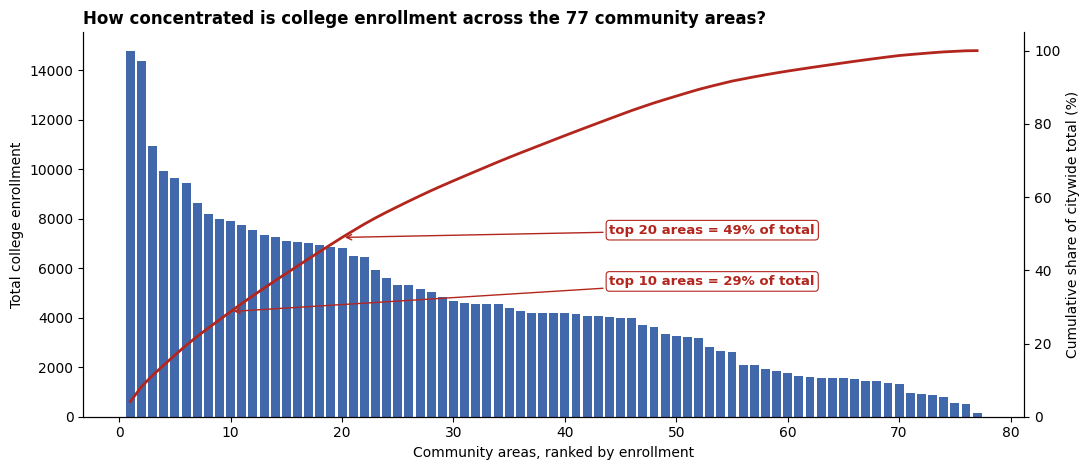

In [19]:
cs.plot_enrollment_distribution(enroll);

**Insight.** The five smallest areas (Oakland 140, Fuller Park 531, Burnside 549, O'Hare 786, Loop 871) include areas that are not primarily residential (O'Hare, the Loop), so low totals likely reflect *how many school seats are located there* rather than low demand. The mean (4,602) sits above the median (4,206), the signature of a right-skewed distribution.

## 6. Joining census data (Problems 11-12)

The second table, `CENSUS_DATA`, adds the **hardship index** per community area. A join on `community_area_number` links each school to its neighborhood's socioeconomic context.

**Problem 11: hardship index for the area of the school with enrollment 4,368.**

In [20]:
p11 = problem('11'); display(p11)

```sql
-- Problem 11: Hardship index of the community area of the school with college enrollment 4368
SELECT hardship_index
FROM CENSUS_DATA CD, CHICAGO_PUBLIC_SCHOOLS_DATA CPS
WHERE CD.community_area_number = CPS.community_area_number
  AND college_enrollment = 4368;
```

,hardship_index
0,6.0


**Problem 12: hardship index for the area of the school with the highest enrollment** (uses a sub-query with `ORDER BY ... LIMIT 1`).

In [21]:
p12 = problem('12'); display(p12)

```sql
-- Problem 12: Hardship index of the community area of the school with the highest College Enrollment
SELECT community_area_number, community_area_name, hardship_index
FROM CENSUS_DATA
WHERE community_area_number IN (
    SELECT community_area_number FROM CHICAGO_PUBLIC_SCHOOLS_DATA
    ORDER BY college_enrollment DESC LIMIT 1
);
```

,community_area_number,community_area_name,hardship_index
0,5.0,North Center,6.0


In [22]:
lane = pd.read_csv(ROOT / "data" / "sample_8_schools.csv").query("COLLEGE_ENROLLMENT == 4368")
display(lane[["NAME_OF_SCHOOL", "COLLEGE_ENROLLMENT", "COMMUNITY_AREA_NAME"]])

,NAME_OF_SCHOOL,COLLEGE_ENROLLMENT,COMMUNITY_AREA_NAME
6,Albert G Lane Technical High School,4368,NORTH CENTER


**Insight - the largest school is in a low-hardship area, and both problems answer about the same place.** The school with 4,368 students is **Albert G. Lane Technical High School**, in **North Center**, whose hardship index is **6** (on the index's 1-100 scale, where higher means more hardship). Problem 12 returns the same area (North Center), consistent with Lane Tech being the largest single school.

**An ambiguity worth flagging.** "The community area which has the highest College Enrollment" can mean (a) the area containing the largest single school, which is what the lab's solution computes, or (b) the area with the largest **total** enrollment, which Problem 8 shows is **South Lawndale** (14,793), not North Center. Query `E07` in `sql/extended` answers reading (b); its hardship value is not in the saved outputs, so it needs the full dataset to run.

## 7. Extended analysis (runs on the full dataset)

Beyond the 12 lab problems, `sql/extended/` contains queries for questions the lab does not ask, such as: *Does school type predict safety and attendance? Do safer schools sit in lower-hardship areas? Which areas rank highest and lowest on safety?* They need the full 566-row table, so they execute only when `RealWorldData.db` exists:

In [23]:
if LIVE:
    for f in cs.sql_files("extended"):
        print("\n###", f.stem); display(cs.run_sql_file(con, f).head(12))
else:
    print("Snapshot mode: build the database with `python run_pipeline.py`, then re-run this cell.")
    for f in cs.sql_files("extended"):
        print(" -", f.read_text().splitlines()[0].lstrip("- ").strip())

Snapshot mode: build the database with `python run_pipeline.py`, then re-run this cell.
 - E01: Profile of each school type (ES / MS / HS): size, safety, attendance, college enrollment
 - E02: Average school safety score per community area next to the area's hardship index
 - E03: School-level safety, attendance and misconduct values for correlation analysis
 - E04: NULL-safe version of Problem 5: numeric sort, missing values excluded
 - E05: Completeness of the columns used in this project
 - E06: Community areas ranked by average school safety score (areas with 3+ schools)
 - E07: Problem 12 asks for "the community area with the highest College Enrollment".


## 8. Lessons learned: SQL pitfalls in real data

| Pitfall | Where it appeared | Safe habit |
|---|---|---|
| **Numbers stored as text** (`'96.00%'`) | Attendance columns | `CAST(REPLACE(col,'%','') AS REAL)` before comparing or averaging |
| **NULLs sort first** in ascending order | Problem 5 ranked a school with *no* data as "lowest" | `WHERE col IS NOT NULL`, or `NULLS LAST` / `NULLS FIRST` explicitly |
| **Quoted identifiers** | `"Elementary, Middle, or High School"` | Inspect names with `PRAGMA_TABLE_INFO` first |
| **Comparing to the string `'None'`** | Problem 10 filter | `IS NOT NULL` is explicit and portable |
| **Ties hidden by `MAX()`** | 19 schools share a safety score of 99 | Use `= (SELECT MAX(...))` to return all ties |
| **Ambiguous wording** | Problem 12 | State which interpretation the query implements |
| **Misleading column name** | `COLLEGE_ENROLLMENT` holds school headcounts | Sanity-check values against a few rows before interpreting |

## 9. Conclusions

- **Attendance gaps are a high-school story** in this dataset: 7 of the 8 schools under 70% are high schools, while the best rates (up to 98.4%) are at elementary-level schools, many of them selective programs.
- **Safety scores are widely dispersed** (1 to 99) and 19 schools tie at the top.
- **Enrollment is concentrated** in a minority of community areas (top 10 = 29%).
- **Real data demands defensive SQL**: type casting, NULL handling and quoting matter as much as the query logic.

### Limitations and next steps
- The reported results are the 12 lab problems; deeper cross-tabs (attendance and safety by school type, safety vs. hardship) are provided as SQL in `sql/extended/` but need the full dataset to run.
- Data covers a single school year (2011-12). No causal claims are made from these descriptive queries.
- Next: run the extended queries, add the correlation charts the pipeline generates, and compare safety against the census hardship index across all 77 areas.